# A04 项目最早何时结束，优先改善哪个环节？

输入12项任务的耗时和前置依赖，先找资源充足时的关键路径，再用两名可执行任意任务的成员安排实际日程。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 建立依赖图
有向边u→v表示v必须等u完成。图必须无环，循环依赖会使这个项目无法按定义开始。任务耗时为整数天。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

import networkx as nx
from ortools.sat.python import cp_model
lengths = dict(zip(list("ABCDEFGHIJKL"), [2,3,2,4,3,2,4,2,3,2,1,2]))
edges = [("A","C"),("A","D"),("B","E"),("C","F"),("D","G"),("E","G"),
         ("E","H"),("F","I"),("G","I"),("H","J"),("I","K"),("J","K"),("K","L")]
graph = nx.DiGraph(); graph.add_nodes_from(lengths); graph.add_edges_from(edges)
assert nx.is_directed_acyclic_graph(graph)
pd.DataFrame({"task":list(lengths),"duration":list(lengths.values())}).to_csv(DATA_DIR / "任务.csv", index=False)


## 2. 正向算最早时间，反向算最晚时间
最早开始是所有前置任务完成时间的最大值。最晚开始倒推自项目终点；两者相减为松弛时间，0表示关键任务。

In [3]:
def critical_times(durations, precedences):
    g = nx.DiGraph(); g.add_nodes_from(durations); g.add_edges_from(precedences)
    if not nx.is_directed_acyclic_graph(g): raise ValueError("依赖存在环")
    order = list(nx.topological_sort(g)); early = {}; finish = {}
    for job in order:
        early[job] = max((finish[p] for p in g.predecessors(job)), default=0)
        finish[job] = early[job] + durations[job]
    makespan = max(finish.values(), default=0); late = {}
    for job in reversed(order):
        latest_finish = min((late[s] for s in g.successors(job)), default=makespan)
        late[job] = latest_finish - durations[job]
    return makespan, early, late
lower_bound, early, late = critical_times(lengths, edges)
critical = [j for j in lengths if late[j] == early[j]]
assert all(early[v] >= early[u] + lengths[u] for u,v in edges)
print("资源充足下最短工期", lower_bound, "关键任务", critical)


资源充足下最短工期 16 关键任务 ['A', 'B', 'D', 'E', 'G', 'I', 'K', 'L']


## 3. 加入人员容量：资源竞争可能再推迟
这是完成A10后可回看的求解器扩展。每项任务占一人且不可中断，`add_cumulative`约束任一时刻最多两项任务。独立检查按每天重新统计资源占用。

In [4]:
def resource_schedule(durations, precedences, capacity):
    model = cp_model.CpModel(); horizon = sum(durations.values())
    starts = {}; ends = {}; intervals = []
    for job, d in durations.items():
        starts[job] = model.new_int_var(0, horizon, "start_"+job)
        ends[job] = model.new_int_var(0, horizon, "end_"+job)
        intervals.append(model.new_interval_var(starts[job], d, ends[job], job))
    for u,v in precedences: model.add(starts[v] >= ends[u])
    model.add_cumulative(intervals, [1]*len(intervals), capacity)
    end = model.new_int_var(0,horizon,"project_end")
    model.add_max_equality(end, list(ends.values())); model.minimize(end)
    solver = cp_model.CpSolver(); solver.parameters.max_time_in_seconds=5
    solver.parameters.num_search_workers=1
    status = solver.solve(model)
    result = ({j:int(solver.value(s)) for j,s in starts.items()}
              if status in (cp_model.OPTIMAL, cp_model.FEASIBLE) else None)
    return solver.status_name(status), result
def check_schedule(starts, durations, precedences, capacity):
    if starts is None or set(starts) != set(durations): return False
    if any(s < 0 for s in starts.values()): return False
    if any(starts[v] < starts[u]+durations[u] for u,v in precedences): return False
    end = max(starts[j]+durations[j] for j in durations)
    return all(sum(starts[j] <= t < starts[j]+durations[j] for j in durations) <= capacity for t in range(end))
status, actual = resource_schedule(lengths, edges, 2)
assert actual is not None, f"未获得方案：{status}；UNKNOWN不等于INFEASIBLE。"
assert check_schedule(actual, lengths, edges, 2)
actual_end = max(actual[j]+lengths[j] for j in lengths)
assert actual_end >= lower_bound


## 4. 比较资源充足时缩短任务的影响
关键路径可能不止一条；单独缩短一个关键任务不保证项目一定缩短。这里逐项重算资源充足的关键路径工期，任务最短仍为1天，因此已是1天的K不能再缩短；不能将该敏感性直接套到两人受限排程，后者需要逐项重新求解。

In [5]:
improvements = {}
for job in lengths:
    changed = lengths.copy(); changed[job] = max(1, changed[job]-1)
    improvements[job] = lower_bound - critical_times(changed, edges)[0]
rows = [{"task":j,"duration":lengths[j],"early":early[j],"slack":late[j]-early[j],
         "resource_start":actual[j],"unlimited_one_day_improvement":improvements[j]} for j in lengths]
pd.DataFrame(rows).to_csv(OUT_DIR / "项目时间表.csv", index=False, encoding="utf-8-sig")
for k,j in enumerate(lengths): plt.barh(j,lengths[j],left=actual[j],color="#428c87")
plt.xlabel("天"); plt.title("两名成员容量下的任务时间表")
plt.tight_layout(); plt.savefig(OUT_DIR / "甘特图.png"); plt.close()
save_results({"unlimited_resource_days":lower_bound,"two_worker_days":actual_end,
              "status":status,"critical_tasks":critical,"unlimited_shorten_one_day_effect":improvements},
             f"资源充足下工期为{lower_bound}天；两名成员下得到{actual_end}天计划，状态{status}。"
             f"仅在资源充足模型下，逐项缩短1天（任务最短仍为1天）的工期影响为{improvements}。两人受限计划的缩短效果需要重新求解。")


{
  "unlimited_resource_days": 16,
  "two_worker_days": 17,
  "status": "OPTIMAL",
  "critical_tasks": [
    "A",
    "B",
    "D",
    "E",
    "G",
    "I",
    "K",
    "L"
  ],
  "unlimited_shorten_one_day_effect": {
    "A": 0,
    "B": 0,
    "C": 0,
    "D": 0,
    "E": 0,
    "F": 0,
    "G": 1,
    "H": 0,
    "I": 1,
    "J": 0,
    "K": 0,
    "L": 1
  }
}
资源充足下工期为16天；两名成员下得到17天计划，状态OPTIMAL。仅在资源充足模型下，逐项缩短1天（任务最短仍为1天）的工期影响为{'A': 0, 'B': 0, 'C': 0, 'D': 0, 'E': 0, 'F': 0, 'G': 1, 'H': 0, 'I': 1, 'J': 0, 'K': 0, 'L': 1}。两人受限计划的缩短效果需要重新求解。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

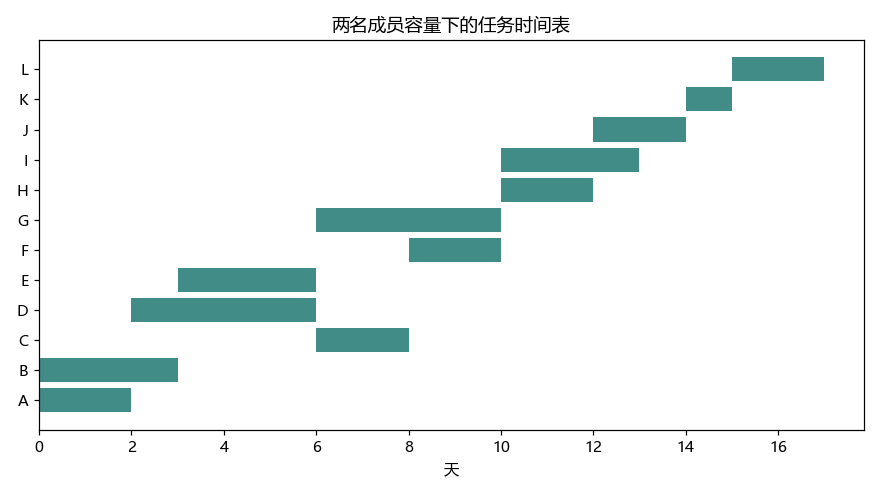

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
关键路径的最早工期先假定资源充足且耗时确定。资源受限扩展使用不可中断任务、同质成员；真实技能差异需要额外约束。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。